# 영업점 추천 시스템 프로젝트 초안

- iM뱅크 수도권 B2B 데이터를 기반으로 규칙 기반 + 유사도 분석을 결합한 프로토타입입니다.
- Day1~Day5 학습 노트의 핵심 아이디어(전처리, CF/MF, 콘텐츠, 평가지표)를 하나의 분석 흐름으로 재구성했습니다.
- 각 단계별로 배경과 가정, 구현 방법을 모두 한글로 상세히 기술해 전략 부서 리뷰를 돕습니다.

## 1. 환경 설정 및 데이터 로드 개요

- csv 파일/imbank_data.csv (CP949 인코딩)을 읽어 전체 데이터 → 수도권 데이터 → 최신 기준년월 데이터 순으로 추출합니다.
- pandas/numpy/scikit-learn을 기본으로 사용하고, 시각화는 matplotlib/seaborn으로 최소한만 수행합니다.
- 생성한 지표는 이후 유사도 분석과 규칙 기반 점수, 평가 단계에서 재사용합니다.

In [1]:
import platform
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import (
    MaxAbsScaler,
    MinMaxScaler,
    PowerTransformer,
    QuantileTransformer,
    RobustScaler,
    StandardScaler,
)

# 노트북은 notebooks/에서 실행되므로 데이터 폴더는 프로젝트 루트 기준으로 찾는다.
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_dir = project_root / "data"

pd.set_option("display.max_columns", 50)

# 스타일을 먼저 적용한다. seaborn-v0_8 스타일이 font.family를 기본값으로 되돌리기 때문이다.
plt.style.use("seaborn-v0_8")
# 한글 폰트: macOS와 Windows는 기본 설치 폰트를 쓰고, 그 밖의 OS는 나눔고딕을 설치해야 한다.
korean_font = {"Darwin": "AppleGothic", "Windows": "Malgun Gothic"}.get(platform.system(), "NanumGothic")
plt.rc("font", family=korean_font)
# 한글 폰트에는 유니코드 마이너스 글리프가 없어 음수 눈금이 깨지므로 ASCII 하이픈으로 표시한다.
plt.rc("axes", unicode_minus=False)

## 2. 데이터 로드 및 기본 현황 파악

- 원천 데이터의 행/열 수, 기준년월 범위, 주요 문자열 컬럼을 빠르게 점검합니다.
- 이후 단계에서 동일한 코드 셀을 다시 실행해도 동일한 결과가 재현될 수 있도록 경로와 인코딩을 고정합니다.

In [2]:
data_path = data_dir / "imbank_data.csv"
df_all = pd.read_csv(data_path, encoding="cp949")

print(f"전체 데이터 크기: {df_all.shape}")
print(f"기준년월 범위: {sorted(df_all['기준년월'].unique())[:3]} ... {sorted(df_all['기준년월'].unique())[-3:]}")
print(f"컬럼({df_all.shape[1]}개): {', '.join(df_all.columns)}")

전체 데이터 크기: (347299, 45)
기준년월 범위: [np.int64(202201), np.int64(202202), np.int64(202203)] ... [np.int64(202410), np.int64(202411), np.int64(202412)]
컬럼(45개): 기준년월, 업종_대분류, 업종_중분류, 사업장_시도, 사업장_시군구, 법인_고객등급, 전담고객여부, 요구불예금잔액, 거치식예금잔액, 적립식예금잔액, 수익증권잔액, 신탁잔액, 퇴직연금잔액, 여신한도금액, 여신_운전자금대출잔액, 여신_시설자금대출잔액, 외환_수출실적금액, 외환_수입실적금액, 신용카드사용금액, 체크카드사용금액, 창구거래금액, 인터넷뱅킹거래금액, 스마트뱅킹거래금액, 폰뱅킹거래금액, ATM거래금액, 자동이체금액, 요구불입금금액, 요구불출금금액, 요구불예금좌수, 거치식예금좌수, 적립식예금좌수, 수익증권좌수, 신탁좌수, 퇴직연금좌수, 여신_운전자금대출좌수, 여신_시설자금대출좌수, 신용카드개수, 외환_수출실적거래건수, 외환_수입실적거래건수, 창구거래건수, 인터넷뱅킹거래건수, 스마트뱅킹거래건수, 폰뱅킹거래건수, ATM거래건수, 자동이체거래건수


## 3. 최신 기준 데이터 추출 및 수도권 플래그 생성

- 전국 데이터를 유지한 상태에서 이후 추천 결과만 수도권으로 제한하기 위해 수도권 여부 컬럼을 생성합니다.
- 최신 기준년월 기준 전체 데이터(df_recent)와 수도권 서브셋(df_recent_metro)을 모두 확인해 표본의 규모와 집중도를 파악합니다.


In [3]:
# 대구·경북 지역을 포함한 전체 최신 데이터 생성
special_exclude_regions = ["경상북도", "대구광역시"]
# 최신 기준년월 계산 및 해당 월 데이터 선택
latest_month = df_all["기준년월"].max()
df_recent = df_all[df_all["기준년월"] == latest_month].copy()

# 수도권 여부 플래그 생성
metro_provinces = ["서울특별시", "경기도", "인천광역시"]
df_recent["수도권여부"] = df_recent["사업장_시도"].isin(metro_provinces)

# 수도권 데이터 서브셋 생성
df_recent_metro = df_recent[df_recent["수도권여부"]].copy()

# 결과 확인
print(f"최신 기준년월({latest_month}) 전체 데이터 행 수: {len(df_recent):,}")
print(f"수도권 데이터 행 수: {len(df_recent_metro):,}")
print("수도권 상위 5개 시군구 빈도:")
display(
    df_recent_metro[["사업장_시도", "사업장_시군구"]]
    .value_counts()
    .head()
    .to_frame(name="법인수")
)

최신 기준년월(202412) 전체 데이터 행 수: 9,712
수도권 데이터 행 수: 931
수도권 상위 5개 시군구 빈도:


법인수
사업장_시도 사업장_시군구     
서울특별시  강남구      142
경기도    화성시       89
서울특별시  영등포구      60
       서초구       58
인천광역시  서구        57

## 4. 전처리: 수치 변환 및 보조 변수 생성

- 금액 컬럼은 천 단위 콤마/문자형을 제거하고 float로 변환합니다.
- 좌수/거래건수 컬럼은 "5개초과 10개이하" 등 구간형 문자열을 중앙값으로 치환합니다.
- 전담고객 여부(Y/N), 법인 고객등급(일반/우수/최우수)을 수치화해 이후 집계 시 활용합니다.

In [4]:
amount_columns = [
    "요구불예금잔액",
    "거치식예금잔액",
    "적립식예금잔액",
    "수익증권잔액",
    "신탁잔액",
    "퇴직연금잔액",
    "여신한도금액",
    "여신_운전자금대출잔액",
    "여신_시설자금대출잔액",
    "외환_수출실적금액",
    "외환_수입실적금액",
    "신용카드사용금액",
    "체크카드사용금액",
    "창구거래금액",
    "인터넷뱅킹거래금액",
    "스마트뱅킹거래금액",
    "폰뱅킹거래금액",
    "ATM거래금액",
    "자동이체금액",
    "요구불입금금액",
    "요구불출금금액"
]

count_columns = [
    "요구불예금좌수",
    "거치식예금좌수",
    "적립식예금좌수",
    "수익증권좌수",
    "신탁좌수",
    "퇴직연금좌수",
    "여신_운전자금대출좌수",
    "여신_시설자금대출좌수",
    "신용카드개수",
    "외환_수출실적거래건수",
    "외환_수입실적거래건수",
    "창구거래건수",
    "인터넷뱅킹거래건수",
    "스마트뱅킹거래건수",
    "폰뱅킹거래건수",
    "ATM거래건수",
    "자동이체거래건수"
]

In [5]:
def clean_amount(series):
    return pd.to_numeric(series.astype(str).str.replace(",", ""), errors="coerce")

def parse_bucket_value(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    if not text or text.lower() in {"nan", "없음"}:
        return np.nan
    digits = re.findall(r"\d+(?:\.\d+)?", text)
    numbers = [float(d) for d in digits]
    if "초과" in text and "이하" in text and len(numbers) >= 2:
        return sum(numbers[:2]) / 2
    if "초과" in text and len(numbers) == 1:
        return numbers[0] * 1.1
    if numbers:
        return numbers[0]
    return np.nan

for col in amount_columns:
    df_recent[col] = clean_amount(df_recent[col])

for col in count_columns:
    df_recent[col] = df_recent[col].apply(parse_bucket_value)

df_recent["전담고객여부"] = df_recent["전담고객여부"].map({"Y": 1, "N": 0}).fillna(0)

grade_map = {"일반": 1, "우수": 2, "최우수": 3}
df_recent["고객등급점수"] = df_recent["법인_고객등급"].map(grade_map)

display(df_recent[amount_columns[:5] + count_columns[:5]].head())

,요구불예금잔액,거치식예금잔액,적립식예금잔액,수익증권잔액,신탁잔액,요구불예금좌수,거치식예금좌수,적립식예금좌수,수익증권좌수,신탁좌수
0,0.16,0.0,0.0,0.0,0.0,7.5,0.0,0.0,0.0,0.0
1,0.03,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0
2,0.24,0.0,0.0,0.0,0.0,15.0,0.0,0.0,0.0,0.0
3,180.00,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,41.00,0.0,0.0,0.0,120.0,7.5,0.0,0.0,0.0,1.0


## 5. 시군구 단위 집계 및 파생 지표 생성

- 동일 시군구 내 법인 고객을 합산하여 현재 영업 기반을 숫자로 나타냅니다.
- 금액/거래 건수는 합계, 전담고객비율과 평균 등급은 평균으로 집계합니다.

In [6]:
group_cols = ["사업장_시도", "사업장_시군구"]

agg_dict = {col: "sum" for col in amount_columns + count_columns}
agg_dict["전담고객여부"] = "mean"
agg_dict["고객등급점수"] = "mean"
agg_dict["법인_고객등급"] = "count"

region_summary = (
    df_recent
    .groupby(group_cols)
    .agg(agg_dict)
    .rename(columns={"법인_고객등급": "법인고객수"})
)

print(f"집계된 시군구 수: {len(region_summary)}")
region_summary.head()

집계된 시군구 수: 85


요구불예금잔액  거치식예금잔액  적립식예금잔액  수익증권잔액    신탁잔액  퇴직연금잔액   여신한도금액  \
사업장_시도 사업장_시군구                                                               
경기도    김포시      2000.68    150.0     27.0     0.0   250.0   250.0    200.0   
       성남시 분당구  2802.41      0.0      0.0     0.0   640.0   640.0  53730.0   
       시흥시       310.02      0.0     84.0     0.0  1390.0   640.0   7080.0   
       안산시 단원구   197.70      0.0      0.0     0.0    28.7    28.7  52890.0   
       안성시      5027.43      0.0      0.0     0.0   310.0   310.0   8820.0   

                여신_운전자금대출잔액  여신_시설자금대출잔액  외환_수출실적금액  외환_수입실적금액  신용카드사용금액  \
사업장_시도 사업장_시군구                                                             
경기도    김포시          12060.0      15720.0       0.00       0.23     26.93   
       성남시 분당구      77459.0      16800.0       0.00       0.43     95.40   
       시흥시          30043.7       6620.0       0.03       0.00     44.66   
       안산시 단원구      67177.0      18050.0       0.01       0.00    108.35   
       안성시          20257.0       6730.0       0.00       0.31     91.13   

                체크카드사용금액  창구거래금액  인터넷뱅킹거래금액  스마트뱅킹거래금액  폰뱅킹거래금액  ATM거래금액  \
사업장_시도 사업장_시군구                                                             
경기도    김포시           0.0     0.0     760.80     110.00      0.0   888.00   
       성남시 분당구       6.2     0.0    6066.80       0.00      0.0  4470.00   
       시흥시           0.0     0.0    1401.79       0.00      0.0   101.70   
       안산시 단원구       0.0     0.0     898.20       0.15      0.0   209.04   
       안성시           0.0     0.0    8877.90     760.40      0.0   460.00   

                 자동이체금액   요구불입금금액   요구불출금금액  요구불예금좌수  거치식예금좌수  적립식예금좌수  \
사업장_시도 사업장_시군구                                                           
경기도    김포시       467.10   2779.81   1893.30     34.5      2.0      3.0   
       성남시 분당구   390.34  10847.01   9876.00     33.5      0.0      0.0   
       시흥시       648.66   2347.90   2897.95     38.5      0.0      2.0   
       안산시 단원구   440.02    715.72   1328.36     44.5      0.0      0.0   
       안성시      1029.69  15589.49  14291.19     29.0      0.0      0.0   

                수익증권좌수  신탁좌수  퇴직연금좌수  여신_운전자금대출좌수  여신_시설자금대출좌수  신용카드개수  \
사업장_시도 사업장_시군구                                                           
경기도    김포시         0.0   1.0     1.0         34.0         15.5    28.5   
       성남시 분당구     0.0   4.0     3.0        100.0          7.5   104.0   
       시흥시         0.0   2.0     1.0         88.5          7.0    56.5   
       안산시 단원구     0.0   3.0     3.0         81.0          8.5    47.0   
       안성시         0.0   2.0     2.0         47.5         12.0    80.0   

                외환_수출실적거래건수  외환_수입실적거래건수  창구거래건수  인터넷뱅킹거래건수  스마트뱅킹거래건수  \
사업장_시도 사업장_시군구                                                           
경기도    김포시              0.0          5.5     0.0      181.0        2.0   
       성남시 분당구          0.0          8.5     0.0      150.5        0.0   
       시흥시              1.0          0.0     0.0       70.5        0.0   
       안산시 단원구          1.0          0.0     0.0      102.0       15.0   
       안성시              0.0          2.0     0.0      194.0       47.5   

                폰뱅킹거래건수  ATM거래건수  자동이체거래건수    전담고객여부    고객등급점수  법인고객수  
사업장_시도 사업장_시군구                                                         
경기도    김포시          0.0     41.0     260.5  0.636364  1.863636     22  
       성남시 분당구      0.0     28.5     174.0  0.761905  2.333333     21  
       시흥시          0.0      2.0     184.5  0.807692  1.923077     26  
       안산시 단원구      0.0      9.5     288.0  0.793103  1.793103     29  
       안성시          0.0      3.5     238.0  0.500000  1.937500     16

In [7]:
deposit_cols = ["요구불예금잔액", "거치식예금잔액", "적립식예금잔액"]
loan_cols = ["여신_운전자금대출잔액", "여신_시설자금대출잔액"]
transaction_cols = ["창구거래금액", "인터넷뱅킹거래금액", "스마트뱅킹거래금액", "폰뱅킹거래금액", "ATM거래금액", "자동이체금액"]
digital_cols = ["인터넷뱅킹거래금액", "스마트뱅킹거래금액", "폰뱅킹거래금액", "자동이체금액"]
card_cols = ["신용카드사용금액", "체크카드사용금액"]
fx_cols = ["외환_수출실적금액", "외환_수입실적금액"]

region_summary["총예금"] = region_summary[deposit_cols].sum(axis=1)
region_summary["총여신"] = region_summary[loan_cols].sum(axis=1)
region_summary["총거래금액"] = region_summary[transaction_cols].sum(axis=1)
region_summary["디지털거래금액"] = region_summary[digital_cols].sum(axis=1)
region_summary["카드거래금액"] = region_summary[card_cols].sum(axis=1)
region_summary["FX거래"] = region_summary[fx_cols].sum(axis=1)

region_summary["디지털거래비중"] = (region_summary["디지털거래금액"] / region_summary["총거래금액"]).fillna(0)
region_summary["자동이체비중"] = (region_summary["자동이체금액"] / region_summary["총거래금액"]).fillna(0)
region_summary["카드거래비중"] = (region_summary["카드거래금액"] / region_summary["총거래금액"]).fillna(0)
region_summary["여신비율"] = (region_summary["총여신"] / (region_summary["총예금"] + 1)).fillna(0)
region_summary["평균등급지수"] = (region_summary["고객등급점수"] / 3).fillna(0)
region_summary["전담고객비율"] = region_summary["전담고객여부"].fillna(0)
region_summary["총자금수요"] = region_summary["총예금"] + region_summary["총여신"]

feature_df = region_summary.reset_index()
feature_df["권역"] = feature_df["사업장_시도"] + " " + feature_df["사업장_시군구"]

feature_df["log_FX거래"] = np.log1p(feature_df["FX거래"])
feature_df["log_총자금수요"] = np.log1p(feature_df["총자금수요"])

feature_df[["권역", "법인고객수", "총예금", "총여신", "디지털거래비중"]].head()

,권역,법인고객수,총예금,총여신,디지털거래비중
0,경기도 김포시,22,2177.68,27780.0,0.601060
1,경기도 성남시 분당구,21,2802.41,94259.0,0.590927
2,경기도 시흥시,26,394.02,36663.7,0.952745
3,경기도 안산시 단원구,29,197.70,85227.0,0.864910
4,경기도 안성시,16,5027.43,26987.0,0.958663


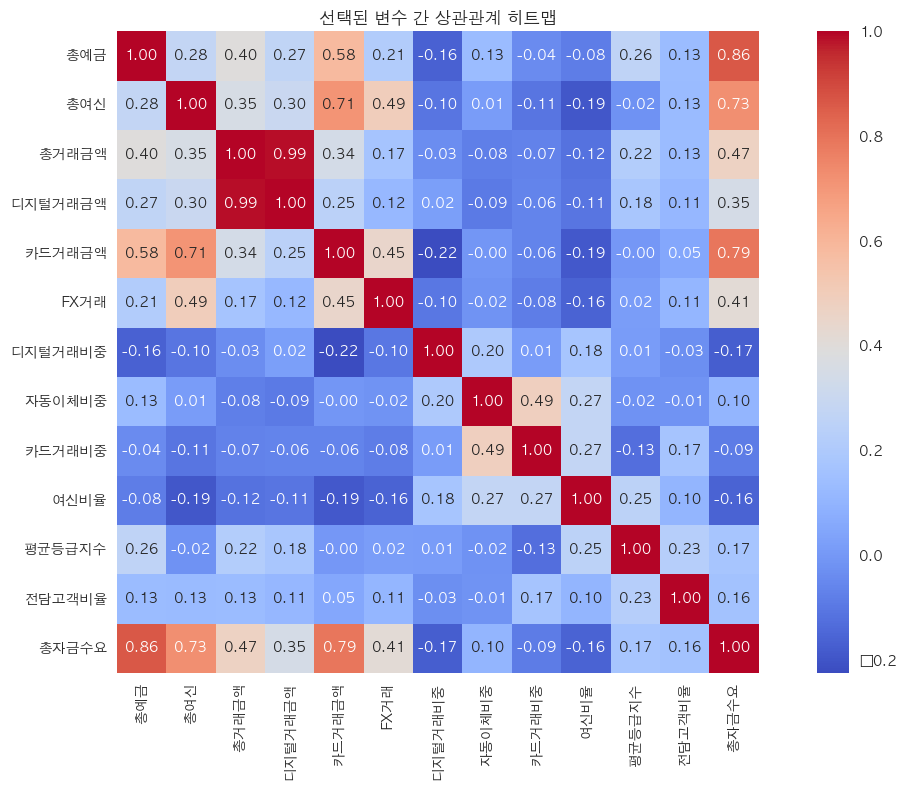

In [8]:
selected_columns = [
    "총예금", "총여신", "총거래금액", "디지털거래금액", "카드거래금액", "FX거래",
    "디지털거래비중", "자동이체비중", "카드거래비중", "여신비율", "평균등급지수", "전담고객비율", "총자금수요"
]

correlation_matrix = feature_df[selected_columns].corr()
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    cbar=True,
    square=True
)
plt.title("선택된 변수 간 상관관계 히트맵")
plt.tight_layout()
plt.show()

### 파생 지표 및 정규화 준비

- 예금/여신/거래 총액, 디지털 비중, 카드 비중, 자동이체 비중 등을 계산해 지역 프로파일을 구성합니다.
- 로그 변환과 정규화를 동시에 적용할 수 있도록 파생 컬럼을 미리 생성합니다.

## 외부 시중은행 위치 데이터 결합

- `시중은행_위치(365,ATM)제외.csv`를 이용해 시중은행 점포 수와 은행 수를 시도/시군구 단위로 집계합니다.
- 내부 법인 데이터(`feature_df`)와 결합하여 법인 고객 대비 외부 점포 밀도를 계산하고, 추천 피처에 경쟁 강도 정보를 추가합니다.


In [9]:
bank_location_path = data_dir / "시중은행_위치(365,ATM)제외.csv"
if not bank_location_path.exists():
    raise FileNotFoundError(f"외부 위치 데이터가 없습니다: {bank_location_path}")

bank_locations = pd.read_csv(bank_location_path, encoding="utf-8-sig")
region_split = bank_locations["검색지역키워드"].str.split(' ', n=1, expand=True)
bank_locations["_시도"] = region_split[0]
bank_locations["_시군구"] = region_split[1].fillna("(미상)").str.strip()

bank_competition = (
    bank_locations
    .groupby(["_시도", "_시군구"])
    .agg(
        시중은행_점포수=("지점명", "count"),
        시중은행_은행수=("은행명", pd.Series.nunique),
    )
    .reset_index()
    .rename(columns={"_시도": "사업장_시도", "_시군구": "사업장_시군구"})
)

feature_df = feature_df.merge(bank_competition, on=["사업장_시도", "사업장_시군구"], how="left")
for col in ["시중은행_점포수", "시중은행_은행수"]:
    feature_df[col] = feature_df[col].fillna(0)

feature_df["시중은행_법인당점포수"] = (
    feature_df["시중은행_점포수"] / feature_df["법인고객수"].replace({0: np.nan})
).replace([np.inf, -np.inf], np.nan).fillna(0)

display_cols = ["권역", "법인고객수", "시중은행_점포수", "시중은행_은행수", "시중은행_법인당점포수"]
display(feature_df[display_cols].head())


,권역,법인고객수,시중은행_점포수,시중은행_은행수,시중은행_법인당점포수
0,경기도 김포시,22,14.0,5.0,0.636364
1,경기도 성남시 분당구,21,27.0,5.0,1.285714
2,경기도 시흥시,26,2.0,2.0,0.076923
3,경기도 안산시 단원구,29,15.0,5.0,0.517241
4,경기도 안성시,16,1.0,1.0,0.062500


In [10]:
feature_cols = [
    # 1) 규모(레벨) – 전체 덩치 + 무역 특성
    'log_총자금수요',   # 예금+여신+거래 규모를 대표
    'log_FX거래',       # 수출입/무역 중심 정도

    # 2) 구조/패턴(비중)
    '디지털거래비중',   # 디지털 채널 의존도
    '자동이체비중',     # 고정·반복 거래 비중 → 관계 결속도
    '카드거래비중',     # 카드 결제 중심도
    '여신비율',         # 여신 중심/예금 중심 구조

    # 3) 고객 질/관계
    '평균등급지수',     # 법인 고객 우량도
    '전담고객비율',     # 전담 RM이 붙은 고객 비율

    # 4) 외부 경쟁 강도
    '시중은행_점포수',
    '시중은행_은행수',
    '시중은행_법인당점포수',
]



feature_df[feature_cols].head()

,log_총자금수요,log_FX거래,디지털거래비중,자동이체비중,카드거래비중,여신비율,평균등급지수,전담고객비율,시중은행_점포수,시중은행_은행수,시중은행_법인당점포수
0,10.307574,0.207014,0.601060,0.209848,0.012098,12.750840,0.621212,0.636364,14.0,5.0,0.636364
1,11.483109,0.357674,0.590927,0.035722,0.009298,33.622981,0.777778,0.761905,27.0,5.0,1.285714
2,10.520259,0.029559,0.952745,0.301401,0.020751,92.814794,0.641026,0.807692,2.0,2.0,0.076923
3,11.355402,0.009950,0.864910,0.284359,0.070020,428.922999,0.597701,0.793103,15.0,5.0,0.517241
4,10.373973,0.270027,0.958663,0.092532,0.008189,5.366884,0.645833,0.500000,1.0,1.0,0.062500


## 6. 유사 지역 벡터 생성 및 레퍼런스 비교

- 75% 분위수 이상의 고성과 지역을 레퍼런스로 정의하고, MinMaxScaler로 정규화한 뒤 코사인 유사도를 계산합니다.
- 유사도 점수는 0~1 범위로 클리핑해 해석을 단순화했습니다.
- 레퍼런스 벡터는 `총자금수요` 컬럼의 상위 25% 데이터를 평균하여 생성됩니다.

### 상세 설명
- **75% 분위수 이상의 고성과 지역을 레퍼런스로 정의한 이유**: 고성과 지역은 특정 지표(예: 총자금수요)에서 우수한 성과를 보이는 지역으로, 이들을 기준으로 다른 지역과의 유사성을 비교하면 추천 시스템의 정확도를 높일 수 있습니다. 75% 분위수는 상위 25%의 데이터를 선택하는 기준으로, 데이터의 극단값(Outlier)을 배제하면서도 고성과 지역을 효과적으로 반영할 수 있습니다.

- **MinMaxScaler를 사용한 정규화**: 각 지표의 값이 서로 다른 범위를 가지므로, 정규화를 통해 모든 지표를 동일한 스케일(0~1)로 변환합니다. 이를 통해 특정 지표가 다른 지표보다 과도하게 영향을 미치는 것을 방지합니다.

- **코사인 유사도를 사용한 이유**: 코사인 유사도는 벡터 간의 방향성을 비교하는 데 유용하며, 벡터의 크기보다는 패턴의 유사성에 초점을 맞춥니다. 이는 지역 간의 상대적인 특성을 비교하는 데 적합합니다.

- **유사도 점수를 0~1로 클리핑**: 계산된 유사도 점수를 0~1 범위로 제한하여 해석을 단순화하고, 추천 결과를 직관적으로 이해할 수 있도록 합니다.

- **레퍼런스 벡터 생성 방식**: `총자금수요` 컬럼의 상위 25% 데이터를 평균하여 레퍼런스 벡터를 생성함으로써, 고성과 지역의 전형적인 특성을 대표하는 기준점을 설정합니다. 이를 통해 다른 지역과의 비교가 명확해지고, 추천 시스템의 신뢰성을 높일 수 있습니다.

In [11]:
reference_quantile = 0.8

scaled_array = MinMaxScaler().fit_transform(feature_df[feature_cols].fillna(0))
reference_threshold = feature_df["총자금수요"].quantile(reference_quantile)
reference_vector = scaled_array[feature_df["총자금수요"] >= reference_threshold].mean(axis=0)

feature_df["유사도점수"] = cosine_similarity(scaled_array, reference_vector.reshape(1, -1)).ravel()
feature_df["유사도점수"] = feature_df["유사도점수"].clip(0, 1)

feature_df.sort_values("유사도점수", ascending=False)[["권역", "총자금수요", "유사도점수"]].head(10)

,권역,총자금수요,유사도점수
34,경상북도 칠곡군,563837.68,0.979681
43,대구광역시 북구,913111.37,0.979521
21,경상북도 구미시,563749.70,0.978077
44,대구광역시 서구,578332.97,0.976084
41,대구광역시 달성군,826469.70,0.973329
42,대구광역시 동구,668638.92,0.969375
40,대구광역시 달서구,1676662.12,0.963635
19,경상북도 경주시,584002.30,0.959193
20,경상북도 고령군,181130.23,0.956006
36,경상북도 포항시 북구,472406.32,0.952335


In [12]:
rule_features = [
    "log_FX거래",
    "디지털거래비중",
    "자동이체비중",
    "카드거래비중",
    "여신비율",
    "평균등급지수",
    "전담고객비율",
]

scaled_rule_df = pd.DataFrame(
    MinMaxScaler().fit_transform(feature_df[rule_features].fillna(0)),
    columns=rule_features,
    index=feature_df.index,
)
scaled_rule_df.head()

,log_FX거래,디지털거래비중,자동이체비중,카드거래비중,여신비율,평균등급지수,전담고객비율
0,0.057438,0.506075,0.268583,0.008394,0.012170,0.137931,0.454545
1,0.099240,0.493528,0.041804,0.006451,0.032354,0.494253,0.642857
2,0.008201,0.941494,0.387820,0.014398,0.089593,0.183024,0.711538
3,0.002761,0.832745,0.365625,0.048583,0.414611,0.084423,0.689655
4,0.074921,0.948821,0.115792,0.005682,0.005030,0.193966,0.250000


In [13]:
# 여기서 만드는 rule_score는 정규화하지 않은 값의 가중합으로, 이후 점수 계산에는 쓰지 않는다.
X = feature_df[feature_cols].drop(columns=["log_총자금수요"]).fillna(0)
y = feature_df["log_총자금수요"].fillna(0)

rf = RandomForestRegressor(random_state=42)
rf.fit(X, y)
importance_weights = rf.feature_importances_ / rf.feature_importances_.sum()

feature_df["rule_score"] = X.mul(importance_weights, axis=1).sum(axis=1)

print("랜덤 포레스트 기반 rule_score 계산 완료!")
print("피처 중요도 (가중치):")
for feature, weight in zip(X.columns, importance_weights):
    print(f"{feature}: {weight:.3f}")

display(feature_df[["권역", "rule_score"]].head())

랜덤 포레스트 기반 rule_score 계산 완료!
피처 중요도 (가중치):
log_FX거래: 0.499
디지털거래비중: 0.034
자동이체비중: 0.069
카드거래비중: 0.078
여신비율: 0.128
평균등급지수: 0.022
전담고객비율: 0.046
시중은행_점포수: 0.021
시중은행_은행수: 0.008
시중은행_법인당점포수: 0.095


,권역,rule_score
0,경기도 김포시,2.211789
1,경기도 성남시 분당구,5.296121
2,경기도 시흥시,12.090918
3,경기도 안산시 단원구,55.528936
4,경기도 안성시,0.934900


## 7. 규칙 기반 점수 및 최종 스코어 계산

- 여신 집중도, 디지털 채널 활성도, 카드/자동이체 비중, 등급/전담 비율 등에 가중치를 주어 규칙 점수를 산출합니다.
- 최종 점수는 유사도 점수와 규칙 점수의 가중 평균으로 계산됩니다. (현재 코드에서는 유사도 80%, 규칙 점수 20%로 설정됨)

In [14]:
# 고정 가중치(합계 1.0). 위 셀의 랜덤 포레스트 중요도를 그대로 쓰지 않는다.
rule_weights = {
    "log_FX거래": 0.505,
    "디지털거래비중": 0.059,
    "자동이체비중": 0.089,
    "카드거래비중": 0.091,
    "여신비율": 0.151,
    "평균등급지수": 0.032,
    "전담고객비율": 0.073,
}
similarity_weight = 0.9
rule_weight = 0.1

feature_df["규칙점수"] = sum(weight * scaled_rule_df[col] for col, weight in rule_weights.items())
feature_df["최종점수"] = similarity_weight * feature_df["유사도점수"] + rule_weight * feature_df["규칙점수"]

feature_df.sort_values("최종점수", ascending=False)[["권역", "유사도점수", "규칙점수", "최종점수"]].head(10)

,권역,유사도점수,규칙점수,최종점수
41,대구광역시 달성군,0.973329,0.493272,0.925323
21,경상북도 구미시,0.978077,0.438384,0.924108
34,경상북도 칠곡군,0.979681,0.418989,0.923612
18,경상북도 경산시,0.948254,0.628848,0.916313
19,경상북도 경주시,0.959193,0.529196,0.916194
40,대구광역시 달서구,0.963635,0.467788,0.914051
43,대구광역시 북구,0.979521,0.323854,0.913955
44,대구광역시 서구,0.976084,0.263101,0.904786
42,대구광역시 동구,0.969375,0.309970,0.903435
30,경상북도 영천시,0.935896,0.587661,0.901073


### 수도권 추천 결과 테이블 및 시각화

- 상위 10개 수도권 권역의 기본 지표와 점수를 확인하고, 막대 그래프로 직관적인 비교를 제공합니다.

In [15]:
recommendations_full = (
    feature_df.sort_values("최종점수", ascending=False)
    .loc[:, ["권역", "사업장_시도", "사업장_시군구", "법인고객수", "총예금", "총여신", "디지털거래비중", "전담고객비율", "유사도점수", "규칙점수", "최종점수"]]
    .reset_index(drop=True)
)

recommendations = (
    recommendations_full[recommendations_full["사업장_시도"].isin(metro_provinces)]
    .reset_index(drop=True)
)

display(recommendations.head(10))


,권역,사업장_시도,사업장_시군구,법인고객수,총예금,총여신,디지털거래비중,전담고객비율,유사도점수,규칙점수,최종점수
0,서울특별시 강남구,서울특별시,강남구,142,279794.38,904199.0,0.963576,0.838028,0.925797,0.469342,0.880151
1,서울특별시 중구,서울특별시,중구,50,3433419.86,614975.0,0.473004,0.860000,0.875703,0.521166,0.840249
2,서울특별시 영등포구,서울특별시,영등포구,60,384633.47,277394.0,0.903900,0.800000,0.871507,0.255432,0.809899
3,경기도 화성시,경기도,화성시,89,9572.09,125719.0,0.873885,0.595506,0.870183,0.266713,0.809836
4,경기도 시흥시,경기도,시흥시,26,394.02,36663.7,0.952745,0.807692,0.865778,0.166844,0.795885
5,경기도 용인시 처인구,경기도,용인시 처인구,21,189.07,61746.0,0.874524,0.571429,0.852786,0.162784,0.783786
6,경기도 용인시 기흥구,경기도,용인시 기흥구,16,160.56,54165.0,0.680091,0.750000,0.846544,0.143965,0.776286
7,경기도 안성시,경기도,안성시,16,5027.43,26987.0,0.958663,0.500000,0.842373,0.129855,0.771121
8,서울특별시 구로구,서울특별시,구로구,16,7673.20,99680.0,0.621131,0.625000,0.843889,0.083855,0.767885
9,경기도 평택시,경기도,평택시,44,3896.99,152343.0,0.855750,0.522727,0.813640,0.325118,0.764787


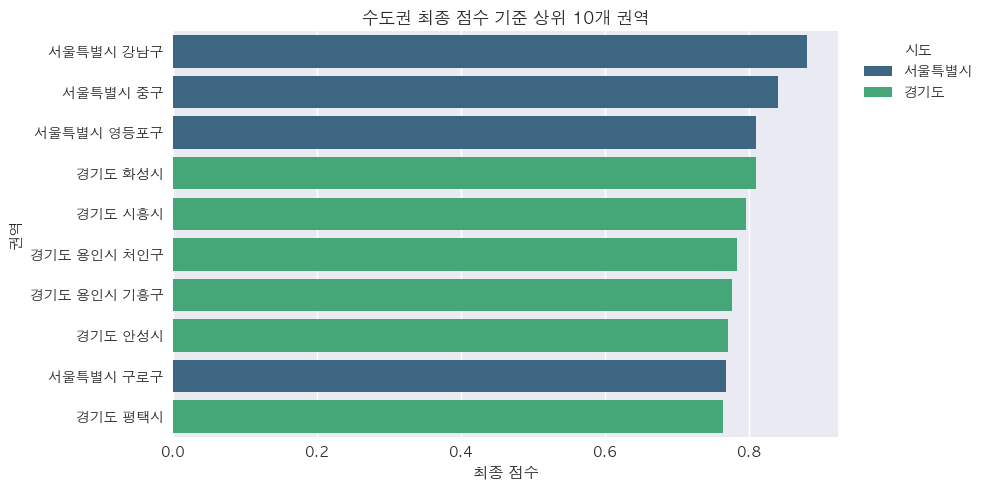

In [16]:
top10 = recommendations.head(10).copy()
plt.figure(figsize=(10, 5))
sns.barplot(
    data=top10,
    x="최종점수",
    y="권역",
    hue="사업장_시도",
    dodge=False,
    palette="viridis"
)
plt.title("수도권 최종 점수 기준 상위 10개 권역")
plt.xlabel("최종 점수")
plt.ylabel("권역")
plt.legend(title="시도", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 8. 간이 추천 성능 평가

- 실제 고성과 지역이 없으므로, `총자금수요`(예금+여신) 상위 10개 수도권 시군구를 "기준 정답"으로 삼아 추천 정확도를 점검합니다.
- 평가 지표로는 Precision@K, Recall@K, Hit Rate@K, NDCG@K를 사용합니다.
- 각 지표는 상위 10개 추천 결과와 기준 정답 간의 일치도를 측정합니다.

In [17]:
def get_top_k_indices(scores, k):
    k = min(k, len(scores))
    return np.argsort(scores)[::-1][:k]


def _top_k_positions(actual_binary, scores, k):
    # 길이가 다르면 정답과 점수가 다른 지역을 가리키게 되므로, 잘라 맞추지 않고 멈춘다.
    if len(actual_binary) != len(scores):
        raise ValueError(
            f"정답 벡터({len(actual_binary)})와 점수 벡터({len(scores)})의 길이가 다릅니다."
        )
    return get_top_k_indices(scores, min(k, len(actual_binary)))


def precision_at_k(actual_binary, scores, k):
    idx = _top_k_positions(actual_binary, scores, k)
    return actual_binary[idx].sum() / len(idx) if len(idx) > 0 else np.nan


def recall_at_k(actual_binary, scores, k):
    idx = _top_k_positions(actual_binary, scores, k)
    total_relevant = actual_binary.sum()
    return actual_binary[idx].sum() / total_relevant if total_relevant > 0 else np.nan


def hit_rate_at_k(actual_binary, scores, k):
    idx = _top_k_positions(actual_binary, scores, k)
    return 1.0 if actual_binary[idx].sum() > 0 else 0.0


def ndcg_at_k(actual_binary, scores, k):
    idx = _top_k_positions(actual_binary, scores, k)
    dcg = 0.0
    for rank, pos in enumerate(idx, start=1):
        rel = actual_binary[pos]
        if rel > 0:
            dcg += (2 ** rel - 1) / np.log2(rank + 1)
    ideal = np.sort(actual_binary)[::-1][:len(idx)]
    idcg = 0.0
    for rank, rel in enumerate(ideal, start=1):
        if rel > 0:
            idcg += (2 ** rel - 1) / np.log2(rank + 1)
    return dcg / idcg if idcg > 0 else np.nan

In [18]:
k = 10
feature_df_metro = feature_df[feature_df["사업장_시도"].isin(metro_provinces)].copy()
ordered = feature_df_metro.sort_values("최종점수", ascending=False).reset_index(drop=True)

benchmark = set(feature_df_metro.nlargest(min(k, len(feature_df_metro)), "총자금수요")["권역"])

ordered["기준정답여부"] = ordered["권역"].isin(benchmark).astype(int)
score_vector = ordered["최종점수"].values
actual_vector = ordered["기준정답여부"].values

metrics = {
    f"Precision@{k}": precision_at_k(actual_vector, score_vector, k),
    f"Recall@{k}": recall_at_k(actual_vector, score_vector, k),
    f"HitRate@{k}": hit_rate_at_k(actual_vector, score_vector, k),
    f"NDCG@{k}": ndcg_at_k(actual_vector, score_vector, k),
}
pd.Series(metrics)

Precision@10    0.500000
Recall@10       0.500000
HitRate@10      1.000000
NDCG@10         0.627409
dtype: float64

### 특정 지역과 유사한 지역 추천 함수

이 코드는 사용자가 입력한 특정 지역과 유사한 지역을 추천하는 기능을 제공합니다. 아래는 코드의 주요 흐름과 각 단계에 대한 설명입니다:

#### 함수 정의: `recommend_similar_regions`
- **목적**: 특정 지역(`input_region`)과 유사한 지역을 찾아 추천합니다.
- **입력값**:
  - `input_region` (str): 추천 기준이 되는 지역 (예: "서울특별시 강남구").
  - `feature_df` (pd.DataFrame): 지역별 특징 데이터프레임.
  - `top_n` (int): 추천할 지역의 개수 (기본값: 5).
- **출력값**: 유사한 지역의 추천 결과를 담은 데이터프레임.

#### 주요 단계
1. **입력 지역 확인**:
   - `input_region`이 데이터프레임의 "권역" 컬럼에 존재하는지 확인합니다.
   - 존재하지 않을 경우, `ValueError`를 발생시켜 사용자에게 알립니다.

2. **입력 지역의 특징 벡터 추출**:
   - `feature_cols`에 정의된 특징 컬럼(예: "log_총예금", "log_총여신" 등)을 기준으로, 입력 지역의 데이터를 추출합니다.
   - 이 벡터는 입력 지역의 특성을 나타냅니다.

3. **코사인 유사도 계산**:
   - `cosine_similarity`를 사용하여 입력 지역의 벡터와 모든 지역의 벡터 간 유사도를 계산합니다.
   - 유사도는 0~1 사이의 값으로, 1에 가까울수록 유사도가 높음을 의미합니다.

4. **유사도 점수 추가**:
   - 계산된 유사도를 `feature_df`에 "입력지역_유사도"라는 새로운 컬럼으로 추가합니다.

5. **추천 지역 정렬 및 반환**:
   - 입력 지역을 제외한 나머지 지역들 중에서 유사도가 높은 순서대로 정렬합니다.
   - 상위 `top_n`개의 지역을 선택하여, "권역", "입력지역_유사도", "총예금", "총여신", "디지털거래비중", "최종점수" 컬럼만 반환합니다.

#### 예시 실행
- `input_region`으로 "서울특별시 강남구"를 입력하여 유사한 지역 5개를 추천합니다.
- 만약 "서울특별시 강남구"가 데이터에 없으면 에러 메시지를 출력합니다.

#### 활용 예시
이 함수는 특정 지역과 유사한 특성을 가진 지역을 추천하여, 마케팅 전략 수립, 영업점 배치 최적화, 지역별 특화 서비스 제공 등에 활용될 수 있습니다.

## 스케일러 선택 가이드

아래 스케일러들은 지역 특징 벡터의 정규화/변환에 사용됩니다. 데이터 분포와 이상치, 모델 목적(거리/유사도 기반) 에 따라 적합한 선택이 달라집니다.

- **MinMaxScaler**
  - 사용 시점: 범위를 0~1로 맞춰 각 피처의 상대적 크기만 비교하고 싶을 때.
  - 장점: 해석 직관적(0~1), 거리/코사인 계산에서 특정 피처가 과도하게 지배하는 것을 완화.
  - 주의: 이상치(outlier)에 매우 민감. 최솟값/최댓값이 바뀌면 스케일 전반이 흔들림.

- **StandardScaler**
  - 사용 시점: 각 피처를 평균 0, 표준편차 1로 정규화해 분포(정규에 가깝다 가정) 기반 비교가 적절할 때.
  - 장점: 많은 모델의 기본 가정과 잘 맞음. 스케일 맞춤에 적합.
  - 주의: 이상치에 민감. 극단값이 있으면 평균/표준편차가 왜곡.

- **RobustScaler**
  - 사용 시점: 이상치가 많아 중앙값/사분위수(IQR)를 기준으로 스케일링하고 싶을 때.
  - 장점: outlier 내성이 높아 분포가 치우친 데이터에 안정적.
  - 주의: 값의 절대 크기 정보가 약해질 수 있음. 비교가 상대적 중앙 기반으로 바뀜.

- **MaxAbsScaler**
  - 사용 시점: 양수/음수가 공존하고 희소한 값 또는 절대 최대값을 기준으로 단순 정규화를 원할 때.
  - 장점: 부호 유지, 희소성 보존(특히 벡터화된 특성에 유리).
  - 주의: 단 하나의 큰 절대값(outlier)에 의해 전체 축이 줄어들 수 있음.

- **QuantileTransformer**
  - 사용 시점: 임의 분포를 균일/정규 분포로 매핑해 순위 기반 비교가 더 의미 있을 때.
  - 장점: 분포를 목표 분포로 강제 변환(여기서는 `normal`), 비선형 왜곡을 줄여 비교 가능.
  - 주의: 데이터 수가 적거나 동일값이 많으면 계단 현상/노이즈. 해석이 원 데이터 스케일과 달라짐.

- **PowerTransformer (Yeo-Johnson)**
  - 사용 시점: 왜도(skew)가 큰 피처를 정규성에 가깝게 만들고 싶을 때(음수/0 허용).
  - 장점: 자동 파라미터로 분포 안정화, 대부분의 연속형 데이터에 적용 가능.
  - 주의: 변환 후 값 해석은 원 스케일과 달라짐. 후처리에서 주의.

- **PowerTransformer (Box-Cox)**
  - 사용 시점: 모든 값이 양수이고 로그 유사 변환으로 정규성에 가깝게 만들 때.
  - 장점: 양수 연속형 데이터에서 왜도 완화에 효과적.
  - 주의: 0/음수 값 불가. 본 노트북에서는 0 이하가 있으면 아주 작은 양(shift)을 더해 안전하게 변환 후 사용.

### 추천 선택 기준 요약
- 이상치 많음 → `RobustScaler`, 분포 강제 변환 필요 → `QuantileTransformer`/`PowerTransformer`.
- 단순 범위 정렬/직관적 0~1 해석 → `MinMaxScaler`.
- 정규성 가정 모델/특징 비교 → `StandardScaler`.
- 양수 데이터의 왜도 교정 → `PowerTransformer(Box-Cox)`; 음수 포함 → `PowerTransformer(Yeo-Johnson)`.
- 희소/부호 유지가 중요 → `MaxAbsScaler`.

실무에서는 성능/해석/안정성 트레이드오프를 고려해 `compare_scalers`로 몇 가지를 병행 평가하고, 목표 지표(정확도·다양성·일관성)에 가장 부합하는 조합을 채택하세요.

In [19]:
# 코사인 유사도 계산 시 사용할 피처 목록
sim_features = feature_cols.copy()

_scaler_map = {
    "minmax": MinMaxScaler(),
    "standard": StandardScaler(),
    "robust": RobustScaler(with_centering=True, with_scaling=True),
    "maxabs": MaxAbsScaler(),
    "quantile": QuantileTransformer(output_distribution="normal", n_quantiles=100),
    "power-yeo": PowerTransformer(method="yeo-johnson", standardize=True),
    "power-box": PowerTransformer(method="box-cox", standardize=True),  # 양수 데이터에만 적용 가능
}
special_input_exclude = set(globals().get("special_exclude_regions", ["경상북도", "대구광역시"]))



def _filter_candidates_by_region(df, feature_df, input_region):
    filtered = df[df["권역"] != input_region].copy()
    if "사업장_시도" not in df.columns or not special_input_exclude:
        return filtered

    input_city = feature_df.loc[feature_df["권역"] == input_region, "사업장_시도"].iloc[0]
    if input_city in special_input_exclude:
        filtered = filtered[~filtered["사업장_시도"].isin(special_input_exclude)]
    return filtered



def build_similarity_matrix(df, features, scaler_name="minmax"):
    """정규화 방식(스케일러)에 따라 유사도 계산용 행렬을 생성합니다.
    지원: minmax, standard, robust, maxabs, quantile, power-yeo, power-box
    """
    if scaler_name not in _scaler_map:
        raise ValueError(f"지원하지 않는 스케일러입니다: {scaler_name}")
    scaler = _scaler_map[scaler_name]
    X = df[features].fillna(0).copy()
    # Box-Cox은 모두 양수여야 하므로 음수/0 존재 시 약간의 시프트 적용
    if scaler_name == "power-box":
        # 최소값이 0 이하인 컬럼에 대해 + (abs(min) + 1e-6) 시프트
        shift = (X.min() <= 0)
        if shift.any():
            for col in X.columns[shift]:
                minv = X[col].min()
                X[col] = X[col] + (abs(minv) + 1e-6)
    scaled = scaler.fit_transform(X)
    return scaled


def recommend_similar_regions(input_region, feature_df, top_n=5, scaler_name="minmax"):
    """
    특정 지역과 유사한 지역을 추천합니다.

    Parameters:
        input_region (str): 입력 지역 (예: "서울특별시 강남구")
        feature_df (pd.DataFrame): 지역별 특징 데이터프레임
        top_n (int): 추천할 지역 개수
        scaler_name (str): 'minmax', 'standard', 'robust', 'maxabs', 'quantile', 'power-yeo', 'power-box' 중 선택

    Returns:
        pd.DataFrame: 유사한 지역 추천 결과
    """
    if input_region not in feature_df["권역"].values:
        raise ValueError(f"입력한 지역 '{input_region}'이 데이터에 존재하지 않습니다.")

    sim_matrix = build_similarity_matrix(feature_df, sim_features, scaler_name=scaler_name)
    region_to_idx = {region: idx for idx, region in enumerate(feature_df["권역"])}

    target_idx = region_to_idx[input_region]
    target_vec = sim_matrix[target_idx].reshape(1, -1)
    similarities = cosine_similarity(target_vec, sim_matrix).flatten()

    # 입력 지역의 유사도는 제외/마스킹
    similarities[target_idx] = -1

    # 원본을 보존하기 위해 복사 후 컬럼 추가
    result_df = feature_df.copy()
    result_df[f"입력지역_유사도_{scaler_name}"] = similarities
    filtered_df = _filter_candidates_by_region(result_df, feature_df, input_region)

    recommendations = (
        filtered_df
        .sort_values(f"입력지역_유사도_{scaler_name}", ascending=False)
        .head(top_n)
        .loc[:, ["권역", f"입력지역_유사도_{scaler_name}", "총예금", "총여신", "디지털거래비중", "최종점수"]]
        .rename(columns={f"입력지역_유사도_{scaler_name}": "입력지역_유사도"})
        .assign(사용스케일러=scaler_name, 유사도함수="cosine")
    )
    # 순위 컬럼 1..N 추가
    recommendations = recommendations.reset_index(drop=True)
    recommendations["순위"] = range(1, len(recommendations) + 1)

    # 보기 좋게 컬럼 순서 재배치
    recommendations = recommendations.loc[:, ["순위", "권역", "입력지역_유사도", "총예금", "총여신", "디지털거래비중", "최종점수", "사용스케일러", "유사도함수"]]

    return recommendations


def compare_scalers(input_region, feature_df, scalers=None, top_n=5):
    """
    여러 스케일러 조합으로 유사 지역 상위 목록을 비교합니다.

    Parameters:
        input_region (str): 기준 지역
        feature_df (pd.DataFrame): 특징 데이터프레임
        scalers (list[str]): 비교할 스케일러 목록
        top_n (int): 스케일러별 상위 추천 개수

    Returns:
        pd.DataFrame: 스케일러별 추천 결과 비교 테이블
    """
    scalers = scalers or ["minmax", "standard", "robust", "maxabs", "quantile", "power-yeo"]
    comparison_rows = []

    for scaler_name in scalers:
        recs = recommend_similar_regions(
            input_region,
            feature_df,
            top_n=top_n,
            scaler_name=scaler_name,
        )
        comparison_rows.append(recs)

    if not comparison_rows:
        raise ValueError("비교할 결과가 없습니다. 스케일러 목록을 확인하세요.")

    table = pd.concat(comparison_rows, ignore_index=True)
    # 스케일러별 내부 순위 보장: 그룹별로 순위 재산출(이미 1..N이지만 안전하게 정렬 후 부여)
    table = (
        table.sort_values(["사용스케일러", "순위"])  # 이미 순위 있음
        .reset_index(drop=True)
    )
    return table



# 예시 실행
input_region = "대구광역시 수성구"
try:
    # 기본 추천 결과 (사용한 함수/스케일러/순위 포함)
    similar_regions = recommend_similar_regions(input_region, feature_df, top_n=5, scaler_name="minmax")
    display(similar_regions)

    # 스케일러별 추천 결과 비교 (각 행에 사용스케일러/유사도함수/순위 포함)
    compare_table = compare_scalers(
        input_region,
        feature_df,
        scalers=["minmax", "standard", "robust", "maxabs", "quantile", "power-yeo"],
        top_n=3,
    )
    display(compare_table)
except ValueError as e:
    print(e)

,순위,권역,입력지역_유사도,총예금,총여신,디지털거래비중,최종점수,사용스케일러,유사도함수
0,1,울산광역시 남구,0.938622,4081.04,59824.0,0.835007,0.826034,minmax,cosine
1,2,경상남도 창원시 진해구,0.925320,833.29,45020.0,0.817948,0.791473,minmax,cosine
2,3,부산광역시 영도구,0.910463,7055.51,137150.0,0.711778,0.813800,minmax,cosine
3,4,경상남도 함안군,0.905527,3369.60,114786.0,0.994252,0.809871,minmax,cosine
4,5,경기도 용인시 기흥구,0.897764,160.56,54165.0,0.680091,0.776286,minmax,cosine


,순위,권역,입력지역_유사도,총예금,총여신,디지털거래비중,최종점수,사용스케일러,유사도함수
0,1,부산광역시 영도구,0.980757,7055.51,137150.0,0.711778,0.813800,maxabs,cosine
1,2,경상남도 창원시 진해구,0.980634,833.29,45020.0,0.817948,0.791473,maxabs,cosine
2,3,울산광역시 남구,0.978659,4081.04,59824.0,0.835007,0.826034,maxabs,cosine
3,1,울산광역시 남구,0.938622,4081.04,59824.0,0.835007,0.826034,minmax,cosine
4,2,경상남도 창원시 진해구,0.925320,833.29,45020.0,0.817948,0.791473,minmax,cosine
5,3,부산광역시 영도구,0.910463,7055.51,137150.0,0.711778,0.813800,minmax,cosine
6,1,부산광역시 사상구,0.424453,5489.34,153118.0,0.510389,0.788949,power-yeo,cosine
7,2,부산광역시 영도구,0.303202,7055.51,137150.0,0.711778,0.813800,power-yeo,cosine
8,3,대전광역시 유성구,0.292642,936.23,99910.0,0.801821,0.704410,power-yeo,cosine
9,1,부산광역시 사상구,0.946370,5489.34,153118.0,0.510389,0.788949,quantile,cosine
